<a href="https://colab.research.google.com/github/CharlieboyCR/XS-3159_DOE/blob/main/Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Simulación
Esta simulación genera datos sobre la solución de en R,donde se da la solución de un sistema de ecuaciones lineales, donde se utiliza la librería RhpcBLASctl para restrigir el uso de núcleos y la función SOLVE nativa de R para la solución del sistema

##Cargamos la librerías

In [2]:
install.packages("RhpcBLASctl")
library(RhpcBLASctl)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



##Definimos los factores de diseño y no diseño.

In [7]:
cores_levels <- c(2,4,6)    # Factor A: Número de núcleos a utilizar
system_sizes <- c(2000,4000,8000) # Factor B: Número de ecuaciones o variables, dado que se comportan igual
replications <- 20      #Esta es la cantidad de réplicas por tratamiento, la cual se asigna dura la simulación de forma aleatoria para eliminar sesgos

##Iniciamos la simulación

In [8]:
# Se elige de forma aleatoria los tratamientos a utilizar en la simulación
experiment_grid <- expand.grid(Cores = cores_levels, Size = system_sizes, Rep = 1:replications)

# Se hace de forma aleatoria los tratamientos a simular, dado que puede exister un sesgo por el cuello de botella térmico
experiment_grid <- experiment_grid[sample(nrow(experiment_grid)), ]
experiment_grid$ExecutionTime <- NA

# Se ejecuta el ciclo para el seteo de los parámetros para la simulación
for (i in 1:nrow(experiment_grid)) {
  # Se setean los núcleos a utilizar
  blas_set_num_threads(experiment_grid$Cores[i])
  omp_set_num_threads(experiment_grid$Cores[i])

  n <- experiment_grid$Size[i]

  # Se genera la matriz de coeficientes (mat_A)
  # Adding 'n' to the diagonal ensures the matrix is diagonally dominant and strictly invertible
  mat_A <- matrix(runif(n * n), n, n)
  diag(mat_A) <- diag(mat_A) + n

  # Generate Vector b (Constants)
  vec_b <- runif(n)

  # Se mide el lapso de tiempo para la resolución del sistema
  exec_time <- system.time(solution_x <- solve(mat_A, vec_b))["elapsed"]
  experiment_grid$ExecutionTime[i] <- exec_time

  # Se realiza una limpieza de la memoria según termina el ciclo para eliminar sesgo por limitaciones de memoria
  gc()
}

##Transformación y preparación de los datos

 Cores    Size         Rep        ExecutionTime   
 2:60   2000:60   Min.   : 1.00   Min.   : 0.224  
 4:60   4000:60   1st Qu.: 5.75   1st Qu.: 0.245  
 6:60   8000:60   Median :10.50   Median : 1.696  
                  Mean   :10.50   Mean   : 5.124  
                  3rd Qu.:15.25   3rd Qu.:13.048  
                  Max.   :20.00   Max.   :18.524  

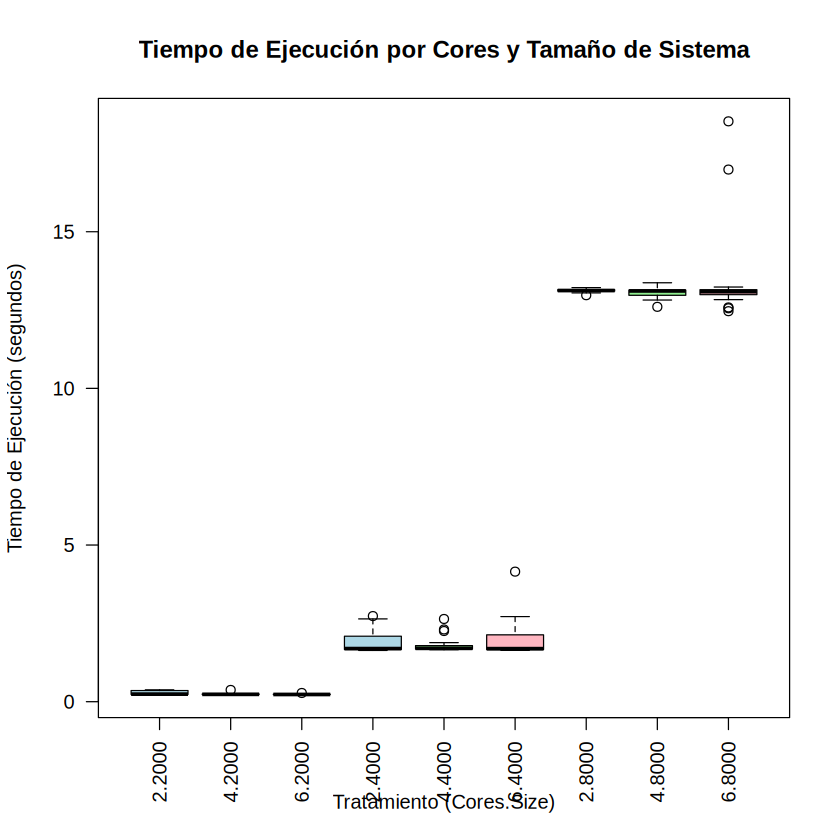

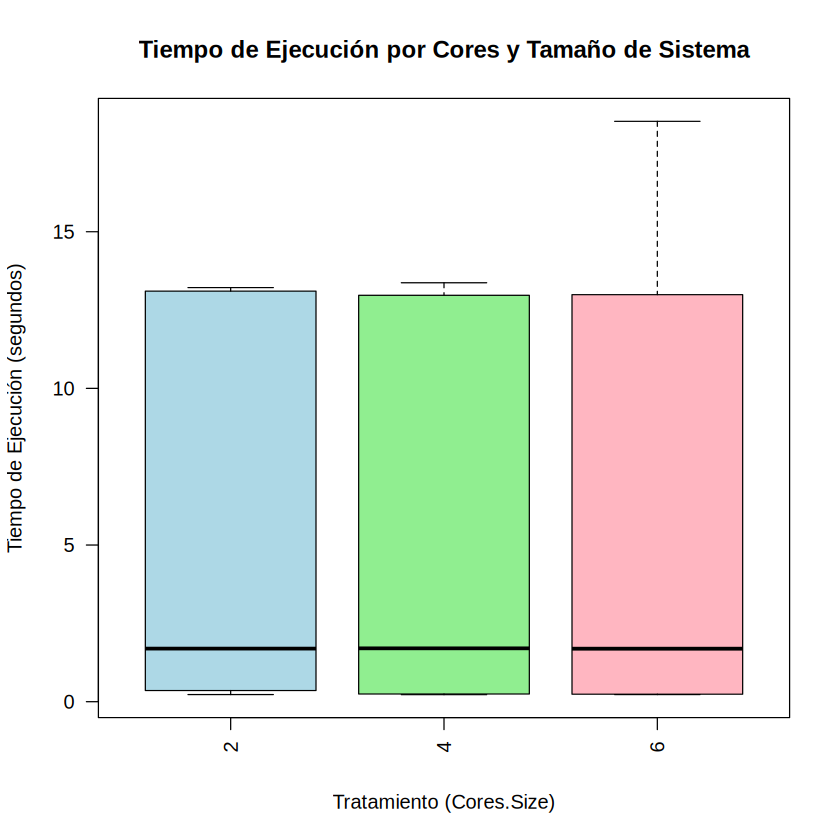

In [19]:
# 4. Se transforma las variables en factores de diseño
experiment_grid$Cores <- as.factor(experiment_grid$Cores)
experiment_grid$Size <- as.factor(experiment_grid$Size)

summary(experiment_grid)

# Creamos un gráfico de caja (boxplot) para comparar los tiempos de ejecución
boxplot(ExecutionTime ~ Cores * Size, data = experiment_grid,
        col = c("lightblue", "lightgreen", "lightpink"),
        las = 2,
        main = "Tiempo de Ejecución por Cores y Tamaño de Sistema",
        xlab = "Tratamiento (Cores.Size)",
        ylab = "Tiempo de Ejecución (segundos)")

boxplot(ExecutionTime ~ Cores, data = experiment_grid,
        col = c("lightblue", "lightgreen", "lightpink"),
        las = 2,
        main = "Tiempo de Ejecución por Cores y Tamaño de Sistema",
        xlab = "Tratamiento (Cores.Size)",
        ylab = "Tiempo de Ejecución (segundos)")


In [20]:
# Realizamos un Análisis de Varianza (ANOVA) para evaluar el impacto de los factores y su interacción
anova_model <- aov(ExecutionTime ~ Cores * Size, data = experiment_grid)
summary(anova_model)

             Df Sum Sq Mean Sq  F value Pr(>F)    
Cores         2      1     0.6    1.781  0.172    
Size          2   5979  2989.6 9343.908 <2e-16 ***
Cores:Size    4      1     0.3    0.828  0.509    
Residuals   171     55     0.3                    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = ExecutionTime ~ Cores * Size, data = experiment_grid)

$Cores
        diff         lwr       upr     p adj
4-2 -0.05745 -0.30161619 0.1867162 0.8433812
6-2  0.13255 -0.11161619 0.3767162 0.4064104
6-4  0.19000 -0.05416619 0.4341662 0.1598180



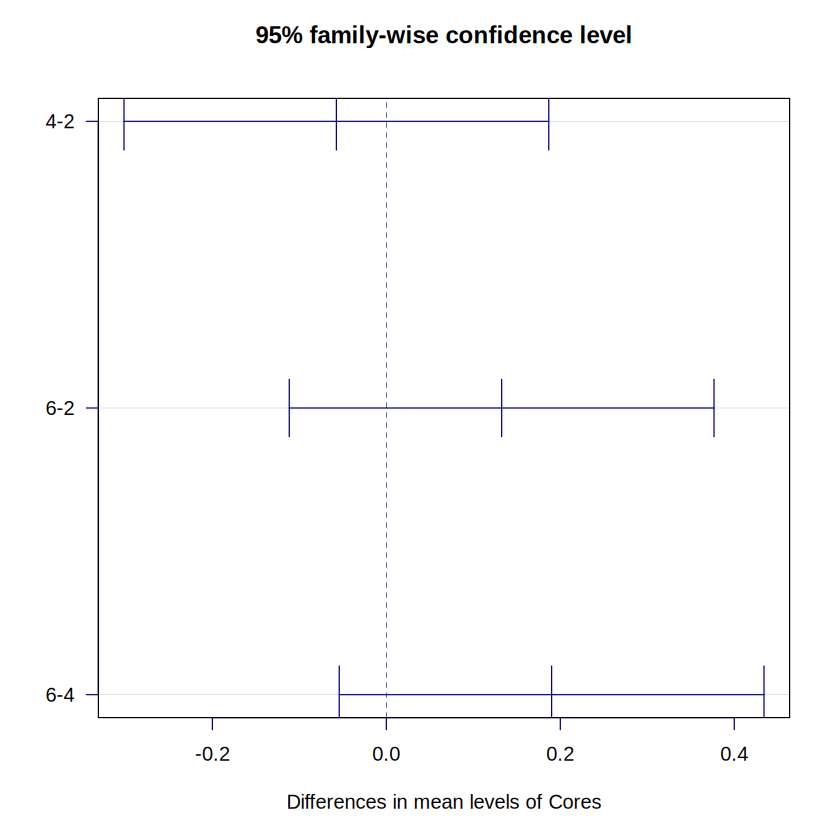

In [21]:
# 1. Ajustamos un modelo ANOVA enfocado en el factor Cores (o usando el modelo completo)
tukey_cores <- TukeyHSD(anova_model, "Cores")
print(tukey_cores)

# 2. Graficamos las diferencias de medias con sus intervalos de confianza
plot(tukey_cores, las = 1, col = "darkblue")

### Simulación Extendida: Incrementando el número de núcleos
Vamos a expandir los niveles de núcleos para incluir, por ejemplo, 8 y 12 núcleos, y observar la tendencia del tiempo de ejecución.

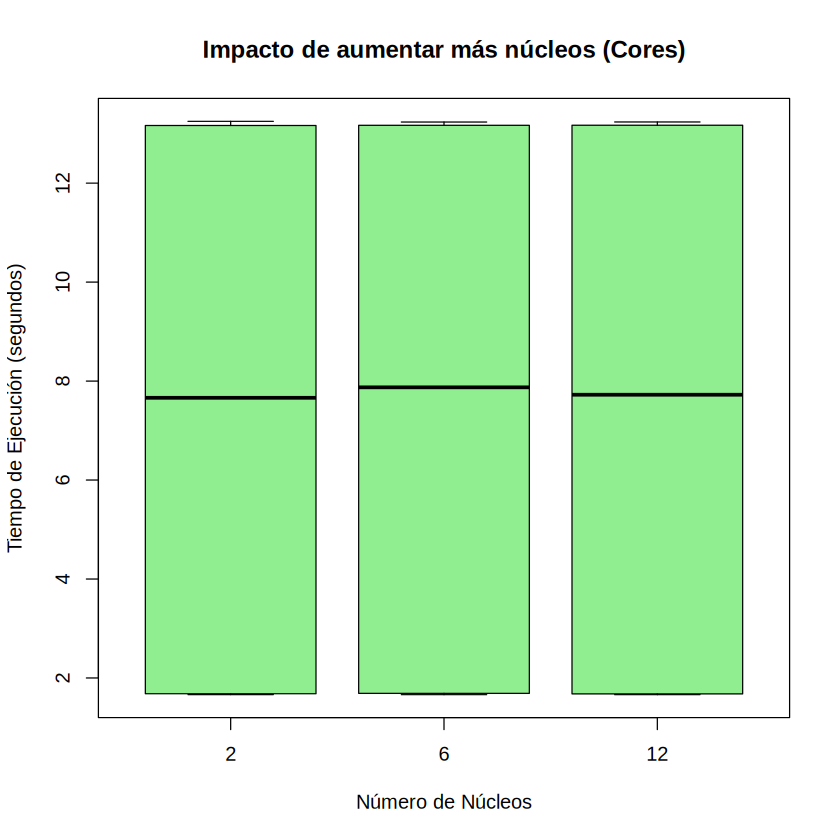

In [22]:
# Definimos un set extendido de cores
cores_extended <- c(2, 6, 12)
system_sizes_extended <- c(4000, 8000) # Usamos tamaños grandes donde se aprecia mejor el paralelismo
reps_extended <- 10

grid_extended <- expand.grid(Cores = cores_extended, Size = system_sizes_extended, Rep = 1:reps_extended)
grid_extended <- grid_extended[sample(nrow(grid_extended)), ]
grid_extended$ExecutionTime <- NA

for (i in 1:nrow(grid_extended)) {
  blas_set_num_threads(grid_extended$Cores[i])
  omp_set_num_threads(grid_extended$Cores[i])

  n <- grid_extended$Size[i]
  mat_A <- matrix(runif(n * n), n, n)
  diag(mat_A) <- diag(mat_A) + n
  vec_b <- runif(n)

  exec_time <- system.time(solve(mat_A, vec_b))["elapsed"]
  grid_extended$ExecutionTime[i] <- exec_time
  gc()
}

grid_extended$Cores <- as.factor(grid_extended$Cores)
grid_extended$Size <- as.factor(grid_extended$Size)

# Graficamos para observar si el aumento de núcleos sigue reduciendo el tiempo o se estanca
boxplot(ExecutionTime ~ Cores, data = grid_extended,
        col = "lightgreen",
        main = "Impacto de aumentar más núcleos (Cores)",
        xlab = "Número de Núcleos",
        ylab = "Tiempo de Ejecución (segundos)")

In [24]:
# Realizamos el ANOVA para el set de datos extendido
anova_extended <- aov(ExecutionTime ~ Cores * Size, data = grid_extended)
summary(anova_extended)

boxplot(ExecutionTime ~ Cores+, data = grid_extended,
        col = "lightgreen",
        main = "Impacto de aumentar más núcleos (Cores)",
        xlab = "Número de Núcleos",
        ylab = "Tiempo de Ejecución (segundos)")

ERROR: Error in parse(text = input): <text>:5:31: unexpected ','
4: 
5: boxplot(ExecutionTime ~ Cores+,
                                 ^


  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = ExecutionTime ~ Cores * Size, data = grid_extended)

$Cores
         diff        lwr       upr     p adj
6-2   0.06770 -0.1037773 0.2391773 0.6104142
12-2  0.03185 -0.1396273 0.2033273 0.8956579
12-6 -0.03585 -0.2073273 0.1356273 0.8697740



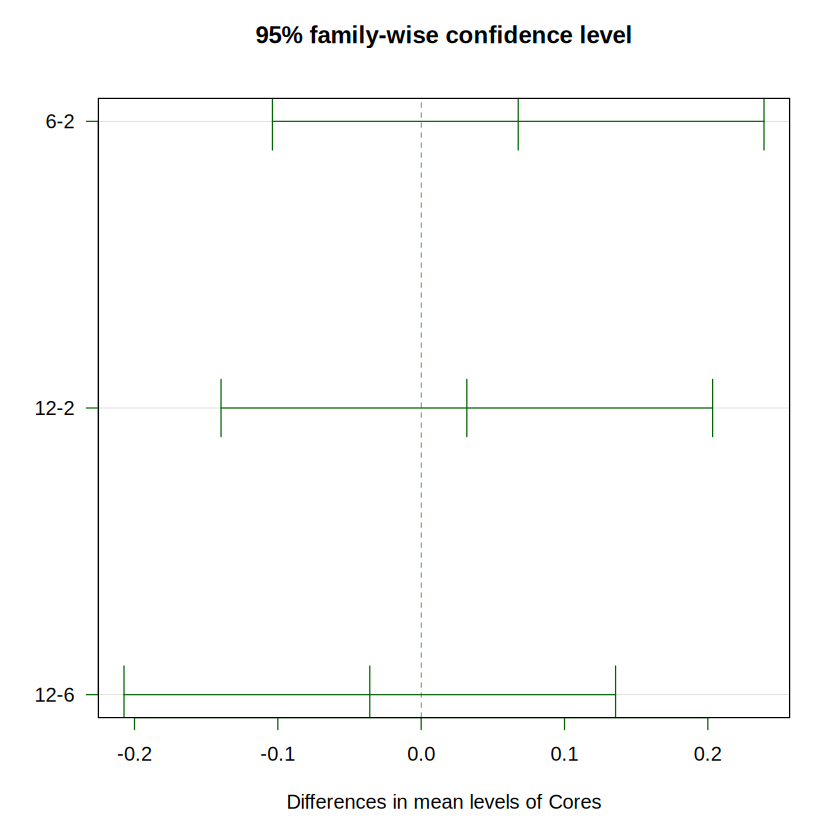

In [25]:
# Aplicamos también la prueba de Tukey para ver cuáles pares de medias difieren significativamente
tukey_extended <- TukeyHSD(anova_extended, "Cores")
print(tukey_extended)

# Graficamos las diferencias de las medias
plot(tukey_extended, las = 1, col = "darkgreen")

### Alternativa: Multiplicación de Matrices (`%*%`)
La multiplicación de matrices es un problema altamente paralelizable ("embarrassingly parallel"). Vamos a evaluar el rendimiento de `A %*% B` con matrices de tamaño $4000 \times 4000$ utilizando 2, 6 y 12 núcleos.

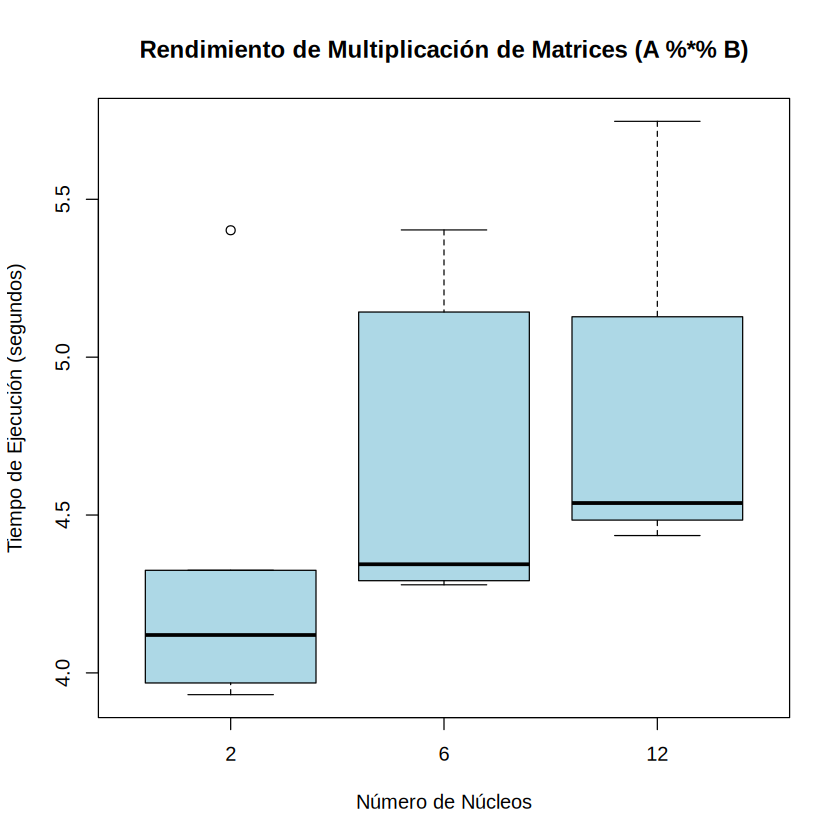

In [26]:
# Configuración del test de multiplicación de matrices
cores_test <- c(2, 6, 12)
n_size <- 4000
reps_mult <- 5

grid_mult <- expand.grid(Cores = cores_test, Rep = 1:reps_mult)
grid_mult$ExecutionTime <- NA

# Ejecución de la simulación de multiplicación
for (i in 1:nrow(grid_mult)) {
  blas_set_num_threads(grid_mult$Cores[i])
  omp_set_num_threads(grid_mult$Cores[i])

  # Generamos dos matrices grandes
  mat_A <- matrix(runif(n_size * n_size), n_size, n_size)
  mat_B <- matrix(runif(n_size * n_size), n_size, n_size)

  # Medimos el tiempo de la multiplicación de matrices
  exec_time <- system.time(mat_C <- mat_A %*% mat_B)["elapsed"]
  grid_mult$ExecutionTime[i] <- exec_time

  gc()
}

grid_mult$Cores <- as.factor(grid_mult$Cores)

# Graficamos los resultados
boxplot(ExecutionTime ~ Cores, data = grid_mult,
        col = "lightblue",
        main = "Rendimiento de Multiplicación de Matrices (A %*% B)",
        xlab = "Número de Núcleos",
        ylab = "Tiempo de Ejecución (segundos)")